# CMF — Bonos bancarios y corporativos + term premium ACM

Notebook de exploración del repo `cmf`:

1. **Flujos** de bonos (cupones y amortizaciones pagadas, CLP) — hoja `FLUJOS`.
2. **Emisiones / colocaciones** — hoja `EMISIONES`.
3. **Term premium ACM** a 30 años (soberano, bancario AAA, corporativo AAA) a partir de los resultados en `analysis/outputs/`.

Correr desde la raíz del repo o desde `analysis/` (detecta la ruta sola).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd() if (Path.cwd() / "cmf_bonos_flujos_emisiones.xlsx").exists() else Path.cwd().parent
XLSX = ROOT / "cmf_bonos_flujos_emisiones.xlsx"
OUT = ROOT / "analysis" / "outputs"
COLORS = {"bancario": "#2a6fdb", "corporativo": "#e07a1f"}

In [2]:
xl = pd.read_excel(XLSX, sheet_name=None)
flujos, emis = xl["FLUJOS"], xl["EMISIONES"]

# Normalizar etiquetas de moneda (vienen con distintas grafías según la fuente)
MONEDA = {"U.F.": "UF", "UF": "UF", "Moneda Nacional": "CLP", "$": "CLP",
          "Dolar EEUU": "USD", "US$": "USD"}
for d in (flujos, emis):
    d["moneda"] = d["moneda_emision"].map(MONEDA).fillna("s/i")

print("FLUJOS", flujos.shape, "| EMISIONES", emis.shape)
flujos.head()

FLUJOS (27012, 14) | EMISIONES (11357, 21)


,fuente,emisor,serie,nro_inscripcion,periodo_reporte,fecha_flujo,regla_fecha,tipo_evento,interes_pagado_clp,amortizacion_pagada_clp,moneda_emision,fecha_vencimiento,nemo,moneda
0,bancario,Banco Bice,36,13/96,2015-01,2015-01-01,dia_vencimiento,cupon_y_amortizacion,"1,070,909.00","9,235,163.00",U.F.,2016-07-01,NaN,UF
1,bancario,Banco Bice,49,12/2010,2015-01,2015-01-01,dia_vencimiento,cupon,"507,933,938.00",0.00,U.F.,2035-07-01,NaN,UF
2,bancario,Banco Bice,50,05/2011,2015-01,2015-01-01,dia_vencimiento,cupon,"2,100,000.00",0.00,Dolar EEUU,2016-07-01,NaN,USD
3,bancario,Banco Bilbao Vizcaya Argentaria. Chile,A,01/2004,2015-01,2015-01-01,dia_vencimiento,cupon,"1,310,247,475.00",0.00,U.F.,2027-12-01,NaN,UF
4,bancario,Banco Bilbao Vizcaya Argentaria. Chile,B7,02/97,2015-01,2015-01-01,dia_vencimiento,cupon,"101,956,375.00",0.00,U.F.,2018-03-01,NaN,UF


## 1. Flujos pagados

In [3]:
flujos["total_pagado_clp"] = flujos[["interes_pagado_clp", "amortizacion_pagada_clp"]].sum(axis=1)
flujos["anio"] = flujos["fecha_flujo"].dt.year

resumen = (flujos.groupby("fuente")
           .agg(emisores=("emisor", "nunique"), series=("serie", "nunique"), registros=("serie", "size"),
                desde=("fecha_flujo", "min"), hasta=("fecha_flujo", "max"),
                interes_MMM=("interes_pagado_clp", lambda s: s.sum() / 1e12),
                amortizacion_MMM=("amortizacion_pagada_clp", lambda s: s.sum() / 1e12)))
resumen  # montos en billones de CLP (1e12)

,emisores,series,registros,desde,hasta,interes_MMM,amortizacion_MMM
fuente,,,,,,,
bancario,22,583,18741,2015-01-01,2026-04-25,144.91,16.98
corporativo,314,100,8271,2016-01-01,2026-05-31,31.62,86.68


In [4]:
pd.crosstab(flujos["tipo_evento"], flujos["fuente"], margins=True)

fuente,bancario,corporativo,All
tipo_evento,,,
amortizacion,5,159,164
cupon,15442,5479,20921
cupon_y_amortizacion,3164,2577,5741
vencimiento_final,130,56,186
All,18741,8271,27012


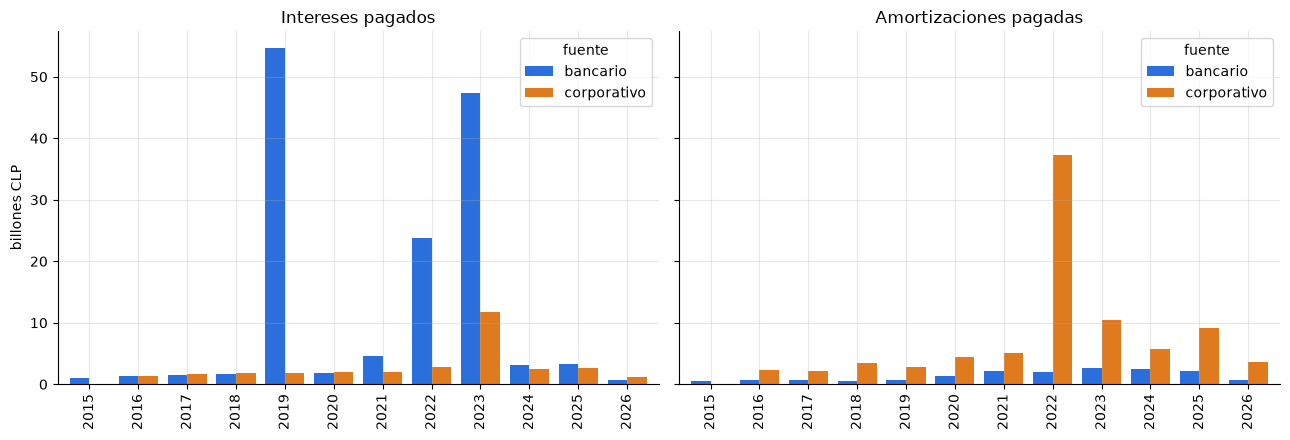

In [5]:
anual = (flujos.groupby(["anio", "fuente"])[["interes_pagado_clp", "amortizacion_pagada_clp"]]
         .sum().div(1e12).unstack("fuente"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, col, title in zip(axes, ["interes_pagado_clp", "amortizacion_pagada_clp"], ["Intereses pagados", "Amortizaciones pagadas"]):
    anual[col].plot.bar(ax=ax, color=[COLORS[c] for c in anual[col].columns], width=.8)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("billones CLP")
plt.tight_layout()

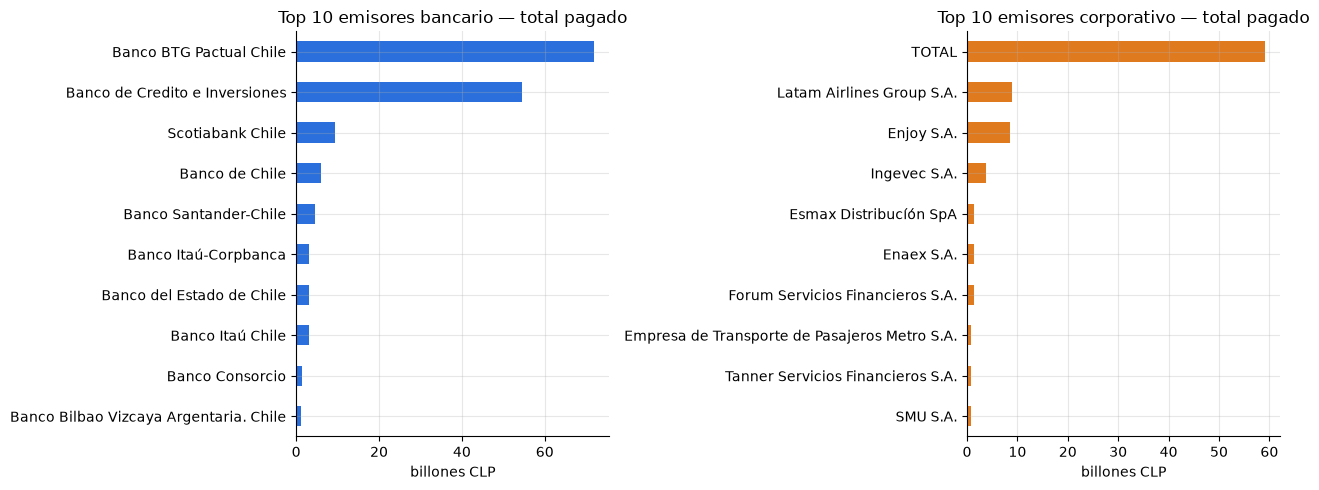

In [6]:
top = (flujos.groupby(["fuente", "emisor"])["total_pagado_clp"].sum().div(1e12)
       .sort_values(ascending=False).groupby(level=0).head(10))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, f in zip(axes, ["bancario", "corporativo"]):
    top[f].sort_values().plot.barh(ax=ax, color=COLORS[f])
    ax.set_title(f"Top 10 emisores {f} — total pagado"); ax.set_xlabel("billones CLP"); ax.set_ylabel("")
plt.tight_layout()

## 2. Emisiones y colocaciones

**Calidad de datos (corporativo):** la hoja trae ~15 filas que son notas al pie del reporte CMF (`(1) CORRESPONDE…`, `*VALOR U.F.(…)=`) y se eliminan. Además, en corporativo `plazo` viene vacío y la tasa está en `tasa_emision_pct` (no en `tasa_colocacion_pct`), así que se construyen campos comunes: `tasa_pct` y `plazo_meses` (vencimiento − emisión/inscripción).

In [7]:
notas = emis["emisor"].astype(str).str.match(r"^\s*[(*]")
print("filas de notas al pie eliminadas:", notas.sum())
emis = emis[~notas].copy()

emis["tasa_pct"] = emis["tasa_colocacion_pct"].where(emis["tasa_colocacion_pct"] > 0, emis["tasa_emision_pct"])
emis.loc[~emis["tasa_pct"].between(0.01, 25), "tasa_pct"] = np.nan   # fuera de rango = no informado / error de unidad

inicio = emis["fecha_emision_nominal"].fillna(emis["fecha_inscripcion"])
plazo_calc = (emis["fecha_vencimiento"] - inicio).dt.days / 30.4375
emis["plazo_meses"] = emis["plazo"].fillna(plazo_calc.where(plazo_calc > 0))

emis.groupby("fuente")[["tasa_pct", "plazo_meses"]].count()

filas de notas al pie eliminadas: 15


,tasa_pct,plazo_meses
fuente,,
bancario,4329,4345
corporativo,4292,1614


In [8]:
emis["fecha_col"] = pd.to_datetime(emis["fecha_colocacion_periodo"], format="%Y-%m", errors="coerce")
emis["anio_col"] = emis["fecha_col"].dt.year.fillna(emis["fecha_emision_nominal"].dt.year)

pd.crosstab(emis["tipo_registro"], emis["fuente"], margins=True)

fuente,bancario,corporativo,All
tipo_registro,,,
aumento_colocacion,1250,523,1773
catalogo,3096,6473,9569
All,4346,6996,11342


In [9]:
pd.crosstab(emis["moneda"], emis["fuente"], margins=True)

fuente,bancario,corporativo,All
moneda,,,
CLP,815,604,1419
UF,3499,3196,6695
USD,31,58,89
s/i,1,3138,3139
All,4346,6996,11342


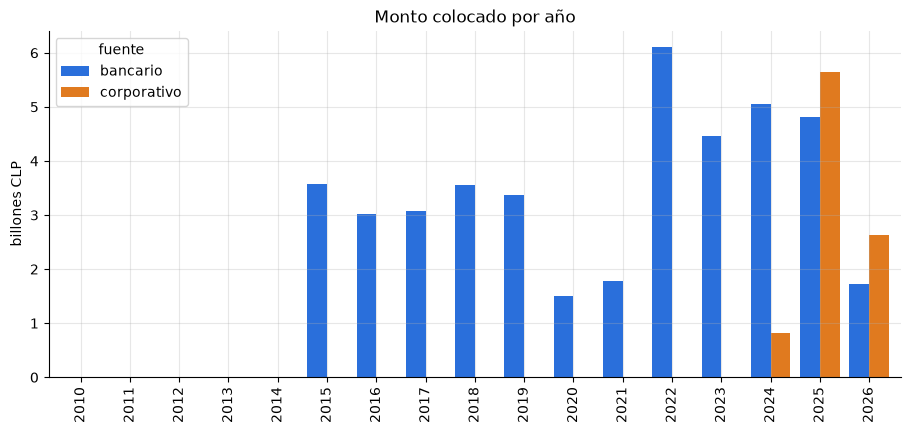

In [10]:
col_anual = (emis.groupby(["anio_col", "fuente"])["monto_colocado_periodo_clp"].sum()
             .div(1e12).unstack("fuente").loc[lambda d: d.index >= 2010])
ax = col_anual.plot.bar(color=[COLORS[c] for c in col_anual.columns], width=.8)
ax.set_title("Monto colocado por año"); ax.set_ylabel("billones CLP"); ax.set_xlabel("")
ax.set_xticklabels([int(x) for x in col_anual.index]);

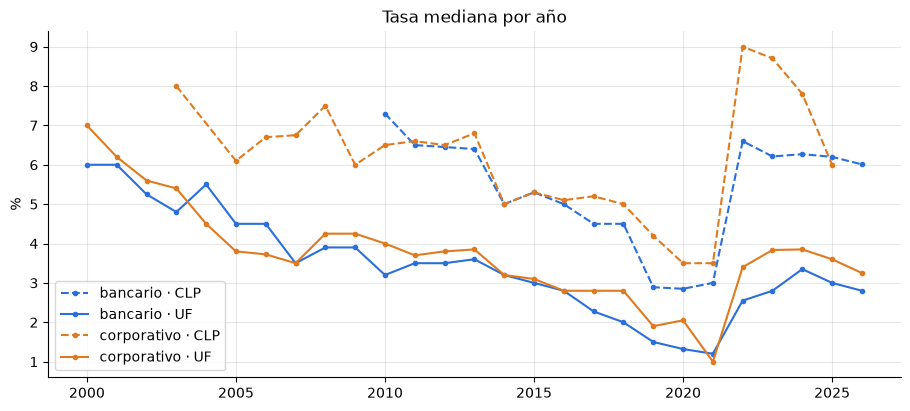

In [11]:
# Tasa (%) por año: bancario = colocaciones del período; corporativo = catálogo (año de inscripción)
emis["anio_ref"] = emis["fecha_col"].dt.year.fillna(emis["fecha_inscripcion"].dt.year)
tasa = (emis.dropna(subset=["tasa_pct", "anio_ref"])
        .query("moneda in ['UF', 'CLP'] and anio_ref >= 2000")
        .groupby(["anio_ref", "fuente", "moneda"])["tasa_pct"].median())

fig, ax = plt.subplots()
for (f, m), s in tasa.groupby(level=[1, 2]):
    if len(s) > 4:
        s.droplevel([1, 2]).plot(ax=ax, marker=".", label=f"{f} · {m}", color=COLORS[f], ls="-" if m == "UF" else "--")
ax.set_title("Tasa mediana por año"); ax.set_ylabel("%"); ax.set_xlabel(""); ax.legend();

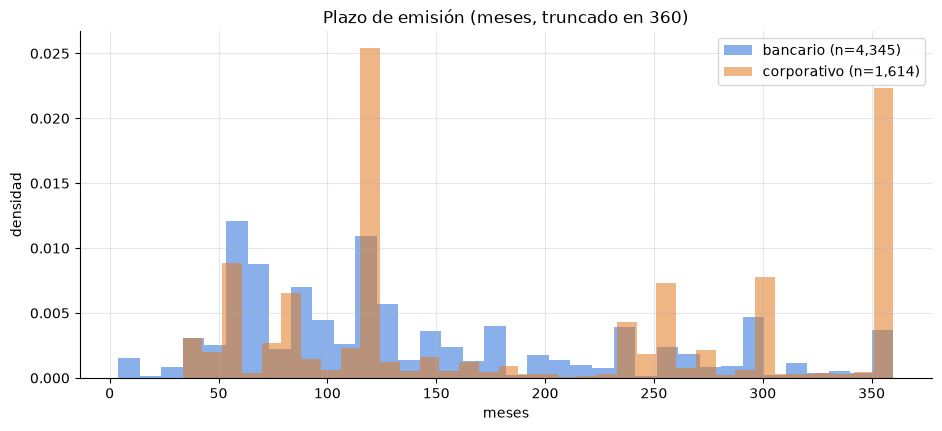

In [12]:
# Distribución del plazo (meses) al emitir
fig, ax = plt.subplots()
for f, g in emis.dropna(subset=["plazo_meses"]).groupby("fuente"):
    g["plazo_meses"].clip(upper=360).plot.hist(ax=ax, bins=36, alpha=.55, color=COLORS[f], label=f"{f} (n={len(g):,})", density=True)
ax.set_title("Plazo de emisión (meses, truncado en 360)"); ax.set_xlabel("meses"); ax.set_ylabel("densidad"); ax.legend();

## 3. Term premium ACM (30 años)

Resultados de `analysis/acm_term_premium.py` (ACM con 3 factores PCA, datos mensuales 2016–2026).
El script requiere `nachometrics_unified` y `curva.parquet`, que no están en el repo, así que acá se leen las salidas ya calculadas.

In [13]:
summary = pd.read_csv(OUT / "term_premium_acm_summary.csv")
summary[["segmento", "curva", "obs_mensuales", "tp30_ultimo_bps", "tp30_media_pp",
         "tp30_min_pp", "tp30_max_pp", "var_explicada", "eig_max_Q", "rmse_precio_bps"]]

,segmento,curva,obs_mensuales,tp30_ultimo_bps,tp30_media_pp,tp30_min_pp,tp30_max_pp,var_explicada,eig_max_Q,rmse_precio_bps
0,Soberano,Gob CERO Pesos,127,-101.00,-1.11,-1.30,-0.93,1.00,1.00,4.73
1,Bancario,CORP Bancarios AAA,127,-260.90,-2.56,-2.89,-2.18,0.99,1.00,21.50
2,Corporativo,CORP AAA,99,-111.60,-1.38,-2.23,-0.70,0.98,1.00,25.11


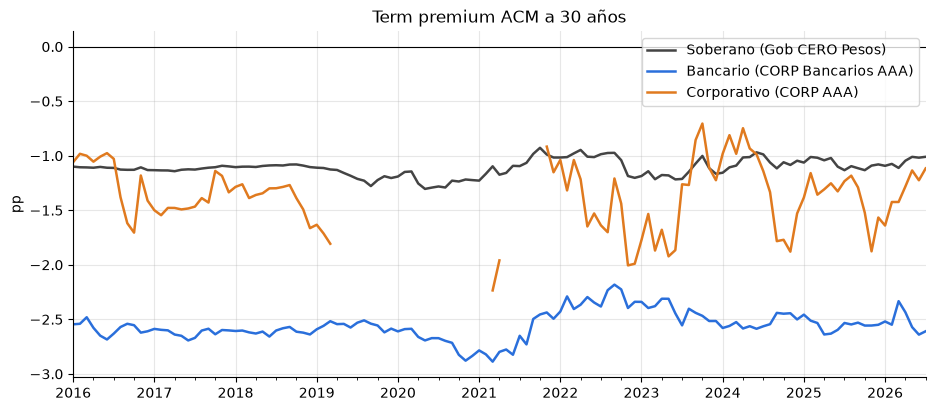

In [14]:
tp30 = pd.read_csv(OUT / "term_premium_acm_30y.csv", parse_dates=["date"], index_col="date")
ax = tp30.plot(color=["#444", COLORS["bancario"], COLORS["corporativo"]], lw=1.8)
ax.axhline(0, color="k", lw=.8)
ax.set_title("Term premium ACM a 30 años"); ax.set_ylabel("pp"); ax.set_xlabel("");

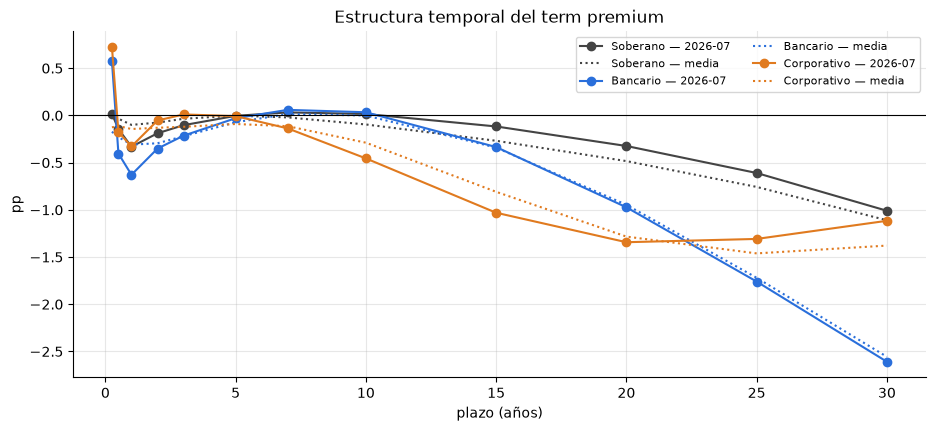

In [15]:
full = pd.read_csv(OUT / "term_premium_acm_full.csv", parse_dates=["date"])
tenores = [c for c in full.columns if c not in ("date", "segmento", "curva")]

fig, ax = plt.subplots()
for (seg, g), c in zip(full.groupby("segmento", sort=False), ["#444", COLORS["bancario"], COLORS["corporativo"]]):
    last = g.loc[g["date"].idxmax(), tenores].astype(float)
    mean = g[tenores].astype(float).mean()
    x = [float(t) for t in tenores]
    ax.plot(x, last.values, marker="o", color=c, label=f"{seg} — {g['date'].max():%Y-%m}")
    ax.plot(x, mean.values, ls=":", color=c, label=f"{seg} — media")
ax.axhline(0, color="k", lw=.8)
ax.set_title("Estructura temporal del term premium"); ax.set_xlabel("plazo (años)"); ax.set_ylabel("pp"); ax.legend(ncol=2, fontsize=8);

,Bancario (CORP Bancarios AAA),Corporativo (CORP AAA)
count,127.00,99.00
mean,-144.60,-28.93
std,12.46,28.99
min,-179.06,-113.78
25%,-152.07,-48.82
50%,-145.50,-26.92
75%,-139.00,-9.66
max,-113.11,29.65


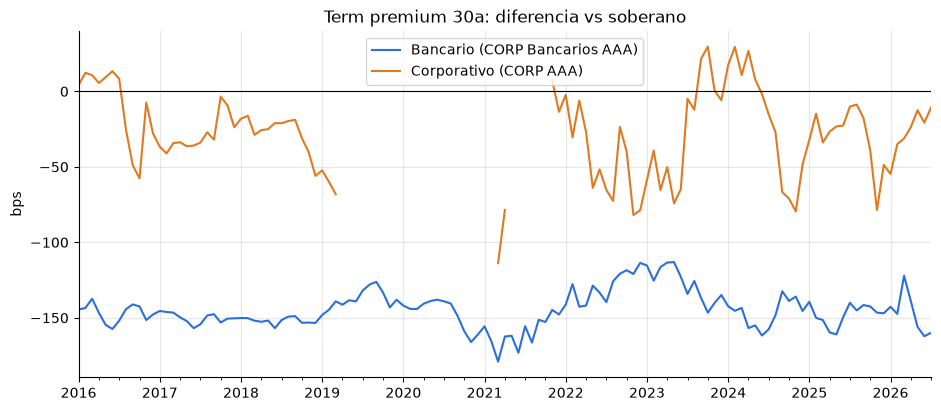

In [16]:
# Spreads de term premium vs soberano
spr = tp30.sub(tp30.iloc[:, 0], axis=0).iloc[:, 1:].mul(100)
ax = spr.plot(color=[COLORS["bancario"], COLORS["corporativo"]])
ax.axhline(0, color="k", lw=.8)
ax.set_title("Term premium 30a: diferencia vs soberano"); ax.set_ylabel("bps"); ax.set_xlabel("");
spr.describe()

**Lectura rápida**

- El term premium a 30 años es **negativo** en los tres segmentos. El bancario AAA es el más negativo (≈ −260 bps) y el soberano el menos negativo (≈ −100 bps).
- Con muestras cortas el **nivel** del premio es sensible al número de factores; conviene leer más las dinámicas y los spreads entre segmentos que el valor absoluto.